# Custom CNN (Model Building)

This notebook builds a Convolutional Neural Network (CNN) for classifying plant leaf images into different disease and healthy categories.

The model will be trained using the preprocessed PlantVillage dataset.

# CNN image ke andar patterns dhundhta hai.
# CNN  architecture 

Input Image
(256 × 256 × 3) 
RGB plant-leaf image model ko input milegi.  

        ↓
     Conv2D
   32 Filters
      (3×3)  Image se basic features jaise edges, lines aur simple textures learn karega.

        ↓
      ReLU  Negative values ko 0 karta hai aur positive values ko retain karta hai.

        ↓
   MaxPooling2D  Feature map ka spatial size reduce karta hai aur important/high activations retain karta hai.
      (2×2)

        ↓
     Conv2D
   64 Filters
      (3×3)
      Pehle layer ke basic features ko combine karke more complex patterns learn karega.

        ↓
      ReLU

        ↓
   MaxPooling2D
      (2×2)
      Phir se spatial dimensions reduce karega.

        ↓
     Conv2D
   128 Filters
      (3×3)
      Aur deeper/more complex features learn karega, potentially disease-related patterns.

        ↓
      ReLU Third convolution ke output par non-linearity apply karega.

        ↓
GlobalAveragePooling2D
Isliye huge 460,800 values ko Dense layer me bhejne ke bajay sirf 128 values milti hain.

        ↓
    Dense (128)  
      ReLU  Learned features ko combine karke classification decision ke liye useful representation banata hai.
      
        ↓
    Dense (36)
     Softmax
     Tumhare dataset me 36 classes hain, isliye 36 output neurons.

        ↓
   Predicted Disease


In [1]:
import os
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt


In [2]:
dataset_path = r"D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village"
print(dataset_path)

D:\Krishi-Sahayak\ml\Plant_disease_detection\dataset\plant_village


In [3]:
IMG_SIZE = (256,256) # Resize images to 256x256 pixels

In [4]:
BATCH_SIZE = 32 # no of images to process in a batch

In [5]:
# to load training dataset

train_dataset = tf.keras.utils.image_dataset_from_directory(  #function to load images from directory and create a tensorflow dataset with llabels
    dataset_path,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 50500 files belonging to 36 classes.
Using 40400 files for training.


In [6]:
# validation dataset  


validation_dataset = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)



Found 50500 files belonging to 36 classes.
Using 10100 files for validation.


In [7]:
val_batches = tf.data.experimental.cardinality(validation_dataset)

print("Validation batches:", val_batches.numpy())

Validation batches: 316


In [8]:
test_dataset = validation_dataset.take(val_batches // 2)
validation_dataset = validation_dataset.skip(val_batches // 2)

In [9]:
print("Train batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Train batches: 1263
Validation batches: 158
Test batches: 158


In [10]:
normalization_layer = tf.keras.layers.Rescaling(1./255)  #means we are scaling the pixel values from 0-255 to 0-1  1. means pixel/255

In [11]:
#applied on the trained dataset
train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [12]:
validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [13]:
test_dataset = test_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

In [14]:
for images, labels in train_dataset.take(1):
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [15]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(256, 256, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [16]:
for images, labels in train_dataset.take(1):
    augmented_images = data_augmentation(images)
    print("Original shape:", images.shape)
    print("Augmented shape:", augmented_images.shape)

Original shape: (32, 256, 256, 3)
Augmented shape: (32, 256, 256, 3)


In [17]:
for images, labels in train_dataset.take(1):
    sample_image = images[0]
    sample_label = labels[0]
    break

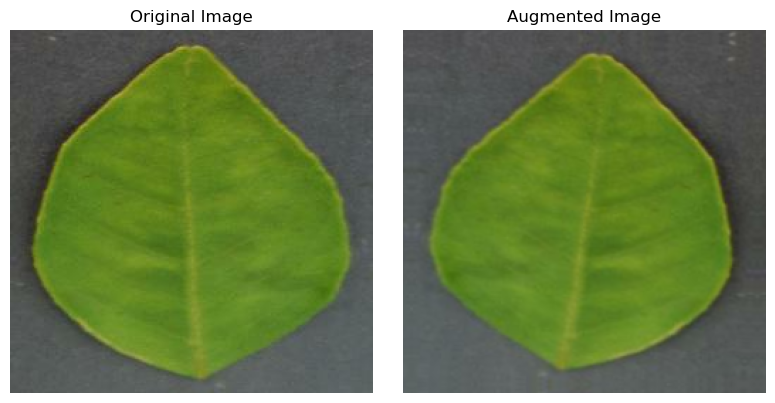

In [18]:
# comparison between original image and augmented image

# sample test
import numpy as np

sample_image_batch = tf.expand_dims(sample_image, axis=0)

augmented_image_batch = data_augmentation(sample_image_batch)

augmented_image = augmented_image_batch[0]

plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(sample_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(augmented_image)
plt.title("Augmented Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
train_dataset = train_dataset.map(
    lambda x, y: (data_augmentation(x), y)
)

In [20]:
for images, labels in train_dataset.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

Images shape: (32, 256, 256, 3)
Labels shape: (32,)


In [21]:
# prefetching the dataset to improve performance

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)


In [22]:
for images, labels in train_dataset.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image shape: (32, 256, 256, 3)
Label shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 0.9480915


In [23]:
classes = os.listdir(dataset_path)

In [24]:
print("Number of classes:", len(classes))
print("Classes:")
for i, class_name in enumerate(classes):
    print(i, ":", class_name)

Number of classes: 36
Classes:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___healthy
6 : Cherry_(including_sour)___Powdery_mildew
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___healthy
10 : Corn_(maize)___Northern_Leaf_Blight
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___healthy
14 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___healthy
22 : Potato___Late_blight
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___healthy
27 : Strawberry___Leaf_scorch
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_blight
31 : Tomato___Leaf_Mold
32 : Tomato___S

In [25]:
# no of classes
class_names = sorted(os.listdir(dataset_path))

num_classes = len(class_names)

print("Number of classes:", num_classes)
print(class_names)

Number of classes: 36
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite

In [26]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
])  #32 mtlb 32 filters, 3x3 kernel size, relu activation function, input shape of 256x256 with 3 channels (RGB)

d:\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [27]:
model.summary()     #formula used = output size = input size - filter size +1
# 256 - 3 + 1 = 254

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

# maxpooling


In [28]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2))
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 896 (3.50 KB)

 Trainable params: 896 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

None is the batch size , 254x254 convolution k naad spatial size (formula use krke) , 32 filters 

 maxpooling2d(2,2) kyuki window dimeansion ko half kr deti h but 32 channels will remain the same , pooling se only height aur width reduce hori h

 Conv2D
→ learns parameters ✅

MaxPooling
→ no parameters ❌
→ only reduces spatial dimensions


In [29]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
])

In [30]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,392 (75.75 KB)

 Trainable params: 19,392 (75.75 KB)

 Non-trainable params: 0 (0.00 B)

In [31]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
])

In [32]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,248 (364.25 KB)

 Trainable params: 93,248 (364.25 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation="relu", input_shape=(256, 256, 3)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),

    layers.GlobalAveragePooling2D()

    
])

In [34]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,248 (364.25 KB)

 Trainable params: 93,248 (364.25 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model = models.Sequential([
    layers.Input(shape=(256, 256, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),

    layers.Dense(num_classes, activation="softmax")
])

In [36]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,404 (446.89 KB)

 Trainable params: 114,404 (446.89 KB)

 Non-trainable params: 0 (0.00 B)

# Compile
Optimizer
   ↓
Weights ko update kaise karna hai?

Loss Function
   ↓
Prediction kitni wrong hai?

Metric
   ↓
Performance ko kaise measure karna hai?

In [37]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [38]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 36)             │         4,644 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 114,404 (446.89 KB)

 Trainable params: 114,404 (446.89 KB)

 Non-trainable params: 0 (0.00 B)

In [39]:
print(tf.config.list_physical_devices('GPU'))

[]


In [40]:
print("Train batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Train batches: 1263
Validation batches: 158
Test batches: 158


# Training

In [41]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [42]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 3556s 3s/step - accuracy: 0.3899 - loss: 2.1719 - val_accuracy: 0.4453 - val_loss: 1.9138
Epoch 2/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1070s 844ms/step - accuracy: 0.6404 - loss: 1.1785 - val_accuracy: 0.5103 - val_loss: 1.9099
Epoch 3/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1029s 814ms/step - accuracy: 0.7435 - loss: 0.8185 - val_accuracy: 0.6812 - val_loss: 1.0843
Epoch 4/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 955s 756ms/step - accuracy: 0.7935 - loss: 0.6547 - val_accuracy: 0.6889 - val_loss: 1.1367
Epoch 5/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 958s 758ms/step - accuracy: 0.8282 - loss: 0.5412 - val_accuracy: 0.6909 - val_loss: 1.0945
Epoch 6/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 961s 760ms/step - accuracy: 0.8516 - loss: 0.4702 - val_accuracy: 0.7308 - val_loss: 0.9651
Epoch 7/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 973s 770ms/step - accuracy: 0.8676 - loss: 0.4154 - val_accuracy: 0.7573 - val_loss: 0.8366
Epoch 8/10
1263/1263 ━━━━━━━━━━━━━━━━━━━━ 1241s 983ms/step - a

In [43]:
best_epoch = np.argmin(history.history["val_loss"]) + 1

print("Best Epoch:", best_epoch)
print("Best Validation Loss:", min(history.history["val_loss"]))
print("Best Validation Accuracy:", history.history["val_accuracy"][best_epoch - 1])


Best Epoch: 9
Best Validation Loss: 0.556958794593811
Best Validation Accuracy: 0.8306899070739746


In [44]:
model.save("custom_cnn_best.keras")